# Example on 40-Gaussian Mixture

We study effect of classifier-free guidance scale on coupling on a toy example with 40-Gaussian Mixture. 

We train conditional flow-matching models on a 2-D Gaussian-mixture target with **40 modes** (the FAB benchmark GMM), whose modes are grouped by
k-means into **4 classes**. All models share the same architecture, data, and classifier-free
guidance (CFG) training and ablate choice of couplings:

| coupling | pairing rule |
|---|---|
| `independent` | noise `e ~ N(0,I)` paired randomly with data `x1` |
| `ot` | **Global Transport**: class-agnostic coupling with mini-batch OT approximation computed via Hungarian algorithm  |
| `ccot` | class-conditional OT: one Hungarian on `\|x1-e\|^2 + beta * \|onehot(c1)-onehot(c0)\|^2` with `beta` large, so the plan reduces to per-class OT |

We can *observe* what each coupling does by generating samples and trajectories, analyzing velocity field and magnitude of guidance vector (prediction gap) `g = v_c - v_u`.

**How to use it.** Set `COUPLINGS` below to any subset of the three couplings and run top to
bottom. Checkpoints are cached in `OUTDIR`, so re-running is cheap; set `RETRAIN = True` to
force fresh training. 

## 1. Configuration

Everything you might want to change lives in this cell: which couplings to train, the ccot
$\beta$ multiplier, training length, and the CFG-scale grids used by the figures.

In [1]:
import os
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import cm, font_manager
from matplotlib.collections import LineCollection
from scipy.cluster.vq import kmeans2

# the couplings come from the repository's optimal_transport.py (the solver used by train_fm.py
# and train_dmf.py); find the repository root from wherever the notebook is run
import sys
_root = os.getcwd()
while not os.path.exists(os.path.join(_root, "optimal_transport.py")):
    if _root == os.path.dirname(_root):
        raise FileNotFoundError("run this notebook from inside the repository")
    _root = os.path.dirname(_root)
sys.path.insert(0, _root)
from optimal_transport import OTPlanSampler

# ---------------- what to run ----------------
COUPLINGS   = ["independent", "ot", "ccot"]   # any subset; order = plot order
BETA_MULT   = 0.68       # ccot class-cost weight: beta = BETA_MULT * mean|x1 - e|^2 ~ 2.7 on this target
TRAIN_STEPS = 8000
RETRAIN     = False       # True -> ignore cached checkpoints
OUTDIR      = "notebook_results"

# ---------------- evaluation grids ----------------
C0        = 0                                  # class inspected in field/trajectory figures
WS_PANEL  = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0]     # CFG scales for sample/trajectory panels
WS_METRIC = np.arange(1.0, 4.01, 0.25)         # fine grid for metric curves
WS_GNORM  = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 6.0]
N_EVAL    = 2000                               # samples per (class, w) for metrics
TS        = (0.0, 0.25, 0.5, 0.75, 0.9)        # time slices for field figures

# ---------------- plot style ----------------
# JetBrains Mono everywhere; the ttf files live in fonts/ (auto-downloaded once).
FONT_DIR = "fonts"
_FONT_URL = "https://github.com/JetBrains/JetBrainsMono/raw/master/fonts/ttf/"
for _fn in ("JetBrainsMono-Regular.ttf", "JetBrainsMono-Bold.ttf"):
    _path = os.path.join(FONT_DIR, _fn)
    if not os.path.exists(_path):
        try:
            os.makedirs(FONT_DIR, exist_ok=True)
            urllib.request.urlretrieve(_FONT_URL + _fn, _path)
        except Exception:
            continue  # offline -> fall back to DejaVu Sans Mono
    font_manager.fontManager.addfont(_path)

plt.rcParams.update({
    "font.family": "monospace",
    "font.monospace": ["JetBrains Mono", "DejaVu Sans Mono"],
    "axes.titlesize": 13,
})

# 4 class colors: dark indigo / lavender / green / orange
CLASS_COLORS = ["#3B3970", "#B0A7DB", "#2F9C7B", "#C76B22"]

def darken(c, f=0.62):
    '''Darker shade of a color, used for scatter-marker edges.'''
    r, g, b = mcolors.to_rgb(c)
    return (f * r, f * g, f * b)

# light-gray target-density contour rings drawn behind every scatter panel
CONTOUR_KW = dict(colors="0.82", linewidths=0.7, linestyles="solid", zorder=0)

STYLE = {"independent": ("Independent",   CLASS_COLORS[0]),
         "ot":          ("Global Transport", CLASS_COLORS[2]),
         "ccot":        (f"Class-cond. OT ($\\beta_m$={BETA_MULT:g})", CLASS_COLORS[3])}

os.makedirs(OUTDIR, exist_ok=True)

## 2. The target and its classes

The FAB GMM (from `lollcat/fab-torch`): 40 mode centers drawn uniformly in $[-40, 40]^2$
(seed 0), per-mode std $\mathrm{softplus}(0.1) \approx 0.744$, everything normalized by the
std of the mode centers so the data sits at unit scale. Classes are **k-means clusters of the
mode centers** (4 clusters, ~10 modes each) — a "class" is a spatial region of the target, and
class-conditional generation must place mass on exactly its own modes. Token `N_CLASS` (= 4)
is the CFG null class.

target: 40 modes, 4 classes, per-mode std 0.0320


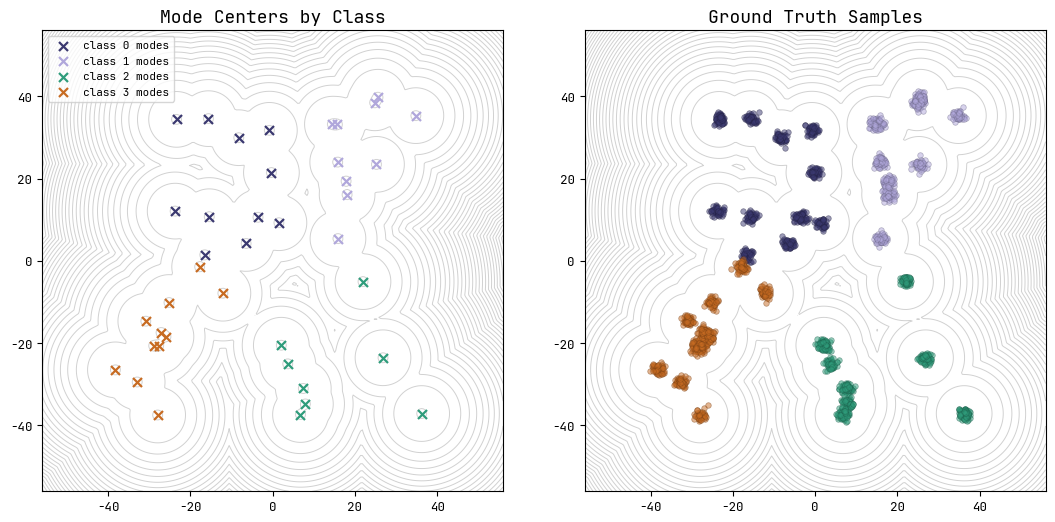

In [2]:
# ---- build the target (seeded, identical to toy_experiment.py) ----
N_MIX, N_CLASS = 40, 4
torch.manual_seed(0)
LOC_SCALING, LOG_VAR_SCALING = 40.0, 0.1
MEAN = ((torch.rand((N_MIX, 2)) - 0.5) * 2 * LOC_SCALING)        # uniform in [-40, 40]^2
STD_RAW = float(F.softplus(torch.tensor(LOG_VAR_SCALING)))       # ~0.744

SCALE = float(MEAN.std())                                        # ~23.25
MODES = (MEAN / SCALE).numpy().astype(np.float32)                # normalized mode centers
STD = STD_RAW / SCALE                                            # ~0.032

# classes = k-means of the mode centers into N_CLASS spatial clusters
np.random.seed(0)
_, MODE_CLASS = kmeans2(MODES, N_CLASS, minit="++", seed=0)
NULL = N_CLASS                                                   # CFG null token


def sample_data(n):
    '''Draw n target samples with their class labels.'''
    idx = np.random.randint(0, N_MIX, n)
    x = MODES[idx] + STD * np.random.randn(n, 2).astype(np.float32)
    return torch.tensor(x), torch.tensor(MODE_CLASS[idx], dtype=torch.long)


def ref_samples(c_val, n):
    '''Ground-truth samples from one class's modes only.'''
    my = np.where(MODE_CLASS == c_val)[0]
    idx = np.random.choice(my, n)
    return MODES[idx] + STD * np.random.randn(n, 2).astype(np.float32)


def log_prob(xy):
    '''Target log-density on normalized coordinates. xy: (n, 2) numpy array.'''
    d2 = ((xy[:, None, :] - MODES[None]) ** 2).sum(-1)
    lp = -d2 / (2 * STD ** 2) - np.log(N_MIX) - np.log(2 * np.pi * STD ** 2)
    m = lp.max(1, keepdims=True)
    return (m + np.log(np.exp(lp - m).sum(1, keepdims=True))).squeeze(1)


# plot windows: B frames the full target, BF the central field region
B  = max(1.4 * (LOC_SCALING / SCALE), float(np.abs(MODES).max()) + 4 * float(STD))
BF = 2.3

# axis ticks labeled in the original (un-normalized) [-40, 40] coordinates
TICKS_RAW = np.array([-40.0, -20.0, 0.0, 20.0, 40.0])

def style_axis(a, box=None, labelsize=9):
    box = B if box is None else box
    a.set_xlim(-box, box); a.set_ylim(-box, box); a.set_aspect("equal")
    a.set_xticks(TICKS_RAW / SCALE, [f"{v:g}" for v in TICKS_RAW])
    a.set_yticks(TICKS_RAW / SCALE, [f"{v:g}" for v in TICKS_RAW])
    a.tick_params(labelsize=labelsize)

def contour_bg(n=250):
    gx = np.linspace(-B, B, n)
    X, Y = np.meshgrid(gx, gx)
    LP = log_prob(np.stack([X.ravel(), Y.ravel()], 1).astype(np.float32)).reshape(n, n)
    return X, Y, LP

X, Y, LP = contour_bg()
print(f"target: {N_MIX} modes, {N_CLASS} classes, per-mode std {STD:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 5.2))
ax[0].contour(X, Y, LP, levels=40, **CONTOUR_KW)
for c in range(N_CLASS):
    m = MODES[MODE_CLASS == c]
    ax[0].scatter(m[:, 0], m[:, 1], s=42, marker="x", color=CLASS_COLORS[c],
                  linewidths=1.6, label=f"class {c} modes")
ax[0].set_title("Mode Centers by Class"); ax[0].legend(fontsize=8)
np.random.seed(0)
ax[1].contour(X, Y, LP, levels=40, **CONTOUR_KW)
for c in range(N_CLASS):
    p = ref_samples(c, 600)
    ax[1].scatter(p[:, 0], p[:, 1], s=16, alpha=0.5, color=CLASS_COLORS[c],
                  edgecolors=darken(CLASS_COLORS[c]), linewidths=0.5)
ax[1].set_title("Ground Truth Samples")
for a in ax:
    style_axis(a)
plt.tight_layout(); plt.show()

In [3]:
OT = OTPlanSampler()   # the repository's exact mini-batch OT / class-conditional OT solver


def couple(coupling, x1, e, c):
    '''Apply the requested (noise, data) coupling to one batch. Rows = data x1, cols = noise e;
    the sampler returns the column assignment, so e[col] is the noise reshuffled to its data.'''
    if coupling == "ot":      # Hungarian on |x1 - e|^2
        return e[OT.sample_plan_with_scipy(x1, e)]
    if coupling == "ccot":    # Hungarian on |x1 - e|^2 + beta * |onehot(c) - onehot(c0)|^2, c0 = c
        return e[OT.sample_conditional_plan_with_scipy(x1, e, c, beta_mult=BETA_MULT)]
    return e


## 3. Model, training, and sampling

We construct a small MLP with input = position $x$, sinusoidal time features,
and a learned class embedding (`N_CLASS + 1` entries — the extra one is the CFG null token).
We train conditional flow matching with 15% class dropout (that dropout is what makes
CFG possible at sampling time), Adam 1e-3, batch 256. The **only** difference between the
models is the `couple(...)` line. 

We sample using Euler 
$v_u + w\,(v_c - v_u)$ over 64 steps; with `return_gnorm=True` it also records
$\|v_c - v_u\|$ along the way (used in the guidance analysis below).

In [4]:
class VF(nn.Module):
    '''Velocity field v(x, t, c): 2-D input, sinusoidal t features, class embedding.'''
    def __init__(self, h=256):
        super().__init__()
        self.cemb = nn.Embedding(N_CLASS + 1, 16)
        self.net = nn.Sequential(
            nn.Linear(2 + 8 + 16, h), nn.SiLU(),
            nn.Linear(h, h), nn.SiLU(),
            nn.Linear(h, h), nn.SiLU(),
            nn.Linear(h, 2))
        self.freqs = torch.arange(1, 5).float() * np.pi

    def forward(self, x, t, c):
        tf = torch.cat([torch.sin(t[:, None] * self.freqs),
                        torch.cos(t[:, None] * self.freqs)], 1)
        return self.net(torch.cat([x, tf, self.cemb(c)], 1))


def train(coupling, steps=8000, bs=256, p_drop=0.15, seed=1):
    torch.manual_seed(seed); np.random.seed(seed)
    m = VF()
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for _ in range(steps):
        x1, c = sample_data(bs)
        e = torch.randn(bs, 2)
        e = couple(coupling, x1, e, c)          # <- the ONLY coupling-dependent line
        c_in = c.clone()
        c_in[torch.rand(bs) < p_drop] = NULL    # CFG class dropout
        t = torch.rand(bs)
        xt = (1 - t[:, None]) * e + t[:, None] * x1
        loss = ((m(xt, t, c_in) - (x1 - e)) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return m


@torch.no_grad()
def sample(m, c_val, n, w, n_steps=64, return_gnorm=False):
    '''Euler CFG sampling: x <- x + dt * (v_u + w (v_c - v_u)).'''
    x = torch.randn(n, 2)
    c = torch.full((n,), c_val, dtype=torch.long)
    cn = torch.full((n,), NULL, dtype=torch.long)
    ts = torch.linspace(0, 1, n_steps + 1)
    gn = []
    for i in range(n_steps):
        t = ts[i].repeat(n); dt = (ts[i + 1] - ts[i]).item()
        vc, vu = m(x, t, c), m(x, t, cn)
        if return_gnorm:
            gn.append((vc - vu).norm(dim=1).mean().item())
        x = x + dt * (vu + w * (vc - vu))
    return (x, np.array(gn)) if return_gnorm else x


# report the realized ccot beta on one probe batch (illustrative only). The sampler does not
# expose it, so repeat its definition: beta = beta_mult * mean(|x1 - e|^2)  (OTPlanSampler.conditional_cost)
if "ccot" in COUPLINGS:
    torch.manual_seed(1); np.random.seed(1)
    x1p, cp_ = sample_data(256)
    beta_probe = BETA_MULT * float((torch.cdist(x1p, torch.randn(256, 2)) ** 2).mean())
    print(f"ccot: beta_mult={BETA_MULT:g} -> beta ~ {beta_probe:.3f} on a probe batch")

models = {}
for cp in COUPLINGS:
    tag = f"fab4_{cp}" + (f"_beta{BETA_MULT:g}" if cp == "ccot" else "")
    fn = os.path.join(OUTDIR, tag + ".pt")
    if os.path.exists(fn) and not RETRAIN:
        m = VF(); m.load_state_dict(torch.load(fn)); m.eval()
        print(f"loaded cached {fn}")
    else:
        print(f"training {cp} ({TRAIN_STEPS} steps) ...")
        m = train(cp, steps=TRAIN_STEPS)
        m.eval(); torch.save(m.state_dict(), fn)
        print(f"saved {fn}")
    models[cp] = m

ccot: beta_mult=0.68 -> beta ~ 2.793 on a probe batch
loaded cached notebook_results/fab4_independent.pt
loaded cached notebook_results/fab4_ot.pt
training ccot (8000 steps) ...


saved notebook_results/fab4_ccot_beta0.68.pt


## 4. Generation results across CFG scales

Each row is one model, each column one CFG scale $w$ (Euler, 64 steps); the last column is
ground truth. Colors are the four classes, over the target contours.

We observe that `Global Transport` couplings remain stable across high CFG scales.

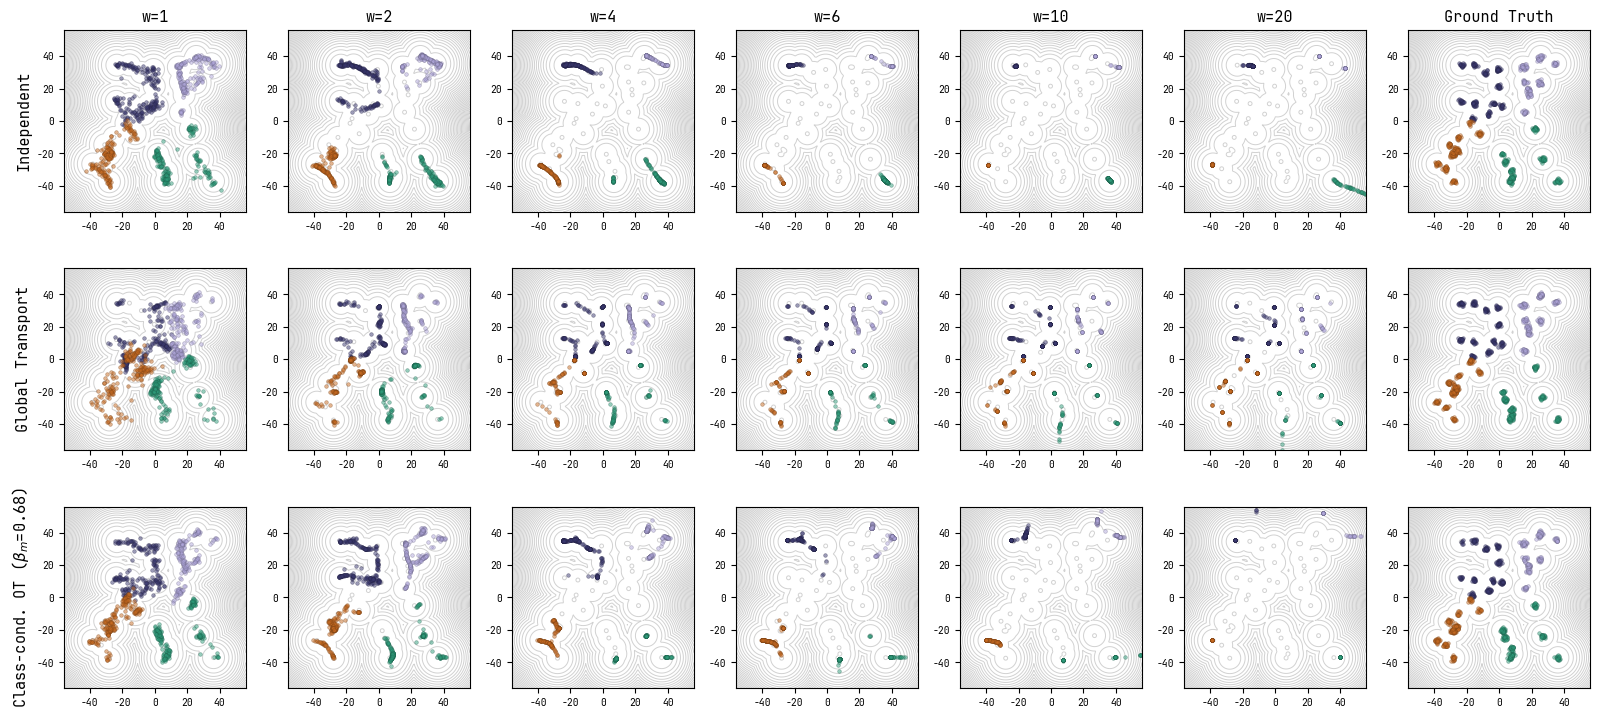

In [5]:
def sample_panel(a, m, w, title, npc=400, s=10, alpha=0.5, gt=False):
    a.contour(X, Y, LP, levels=40, **CONTOUR_KW)
    for c in range(N_CLASS):
        pts = ref_samples(c, npc) if gt else sample(m, c, npc, float(w)).numpy()
        a.scatter(pts[:, 0], pts[:, 1], s=s, alpha=alpha, color=CLASS_COLORS[c],
                  edgecolors=darken(CLASS_COLORS[c]), linewidths=0.4)
    a.set_title(title, fontsize=11)
    style_axis(a, labelsize=7)

# paper figure: one row per coupling, w = 1, 2, 4, 6, 10, 20 + ground truth; saved as a PDF in paper/
PAPER_ROWS   = COUPLINGS
PAPER_WS     = [1.0, 2.0, 4.0, 6.0, 10.0, 20.0]
PAPER_DIR    = "paper"
os.makedirs(PAPER_DIR, exist_ok=True)

torch.manual_seed(11); np.random.seed(11)
nC = len(PAPER_WS) + 1
fig, ax = plt.subplots(len(PAPER_ROWS), nC,
                       figsize=(2.3 * nC, 2.5 * len(PAPER_ROWS)), squeeze=False)
for r, cp in enumerate(PAPER_ROWS):
    for k, w in enumerate(PAPER_WS):
        sample_panel(ax[r, k], models[cp], w, f"w={w:g}" if r == 0 else "", npc=200, s=7)
    sample_panel(ax[r, -1], None, 0, "Ground Truth" if r == 0 else "", npc=200, s=7, gt=True)
    ax[r, 0].set_ylabel(STYLE[cp][0], fontsize=11)
plt.tight_layout()
fig.savefig(os.path.join(PAPER_DIR, "fab4_couplings_cfg_sweep.pdf"),
            bbox_inches="tight")
plt.show()

## 5. Sampling trajectories

Full Euler-CFG trajectories from a **shared** set of noise draws, all conditioned on class 0,
one column per CFG scale. Line color = time (dark = start). Endpoints are classified as
on-a-class-0-mode (green), on a wrong-class mode (orange), or off-distribution (red, not within
$4\sigma$ of any mode); the per-panel text gives the fractions.

We observe Global Transport improves generation when increasing CFG scale.

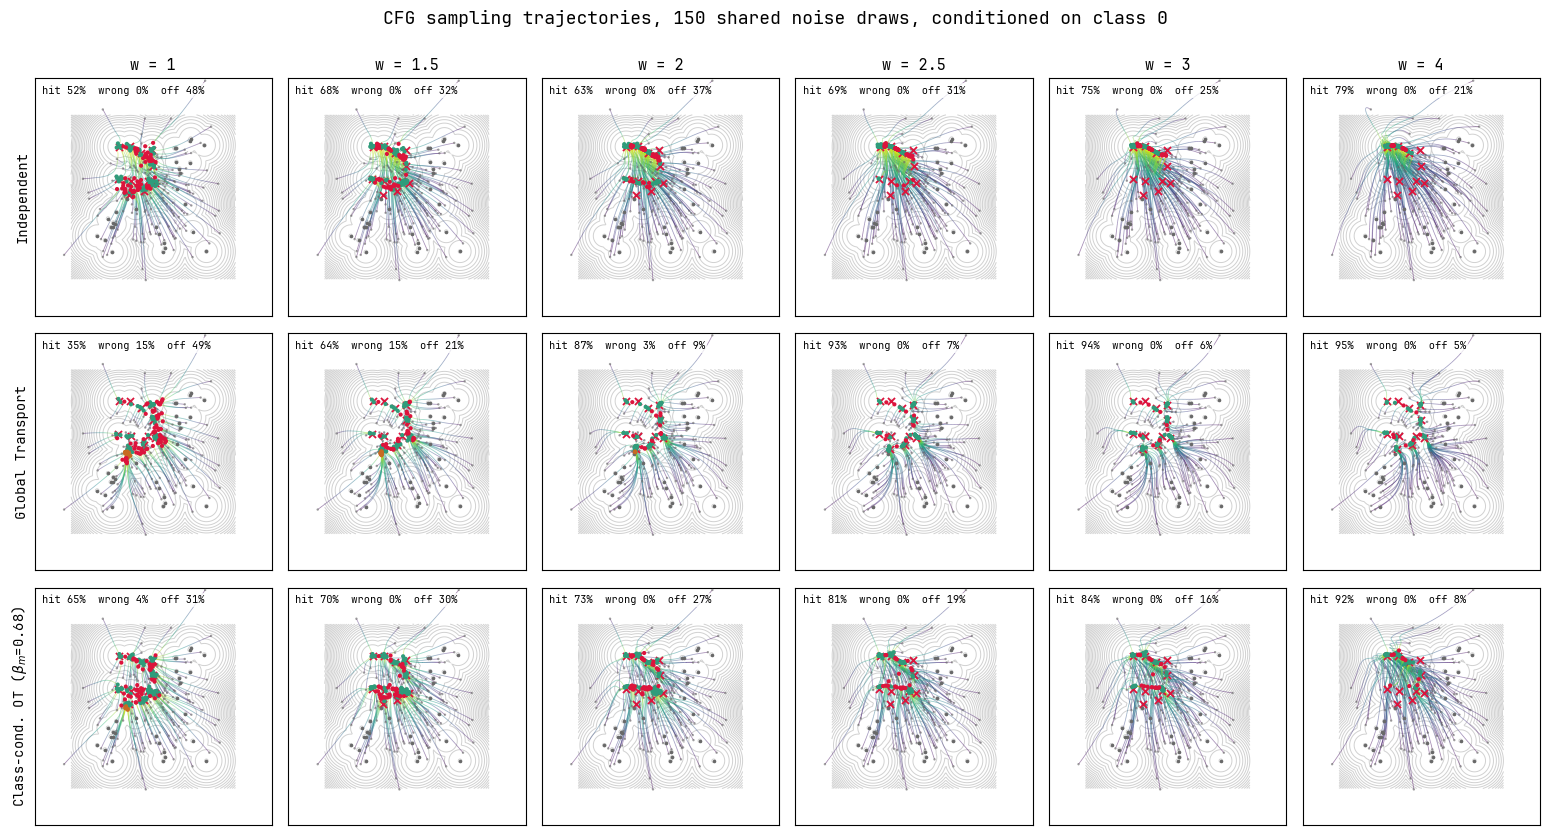

In [6]:
m0 = MODES[MODE_CLASS == C0]        # class-C0 modes (red x in the panels)
mrest = MODES[MODE_CLASS != C0]     # all other modes

N_STEPS = 64
R_HIT = 4.0 * STD

@torch.no_grad()
def sample_traj(m, w, n, seed=0, c_val=C0, n_steps=N_STEPS, x0=None):
    '''Like sample(), but records every state. Returns (n_steps+1, n, 2).'''
    torch.manual_seed(seed)
    x = torch.randn(n, 2) if x0 is None else x0.clone()
    n = len(x)
    c = torch.full((n,), c_val, dtype=torch.long)
    cn = torch.full((n,), NULL, dtype=torch.long)
    ts = torch.linspace(0, 1, n_steps + 1)
    out = [x.numpy().copy()]
    for i in range(n_steps):
        t = ts[i].repeat(n); dt = (ts[i + 1] - ts[i]).item()
        vc, vu = m(x, t, c), m(x, t, cn)
        x = x + dt * (vu + w * (vc - vu))
        out.append(x.numpy().copy())
    return np.stack(out)

def endpoint_outcome(xe):
    '''0 = on a class-0 mode, 1 = on a wrong-class mode, 2 = off-distribution.'''
    d = np.linalg.norm(xe[:, None] - MODES[None], axis=-1)
    nearest, dmin = d.argmin(1), d.min(1)
    out = np.full(len(xe), 2)
    on = dmin < R_HIT
    out[on & (MODE_CLASS[nearest] == C0)] = 0
    out[on & (MODE_CLASS[nearest] != C0)] = 1
    return out

def add_traj_lines(a, T, cmap="viridis", lw=0.55, alpha=0.5):
    S, n = T.shape[0] - 1, T.shape[1]
    segs = np.stack([T[:-1], T[1:]], axis=2).reshape(S * n, 2, 2)
    ts = np.linspace(0, 1, S + 1)
    cvals = np.repeat((ts[:-1] + ts[1:]) / 2, n)
    lc = LineCollection(segs, cmap=cmap, norm=plt.Normalize(0, 1),
                        linewidths=lw, alpha=alpha)
    lc.set_array(cvals)
    a.add_collection(lc)

n_traj = 150
trajs = {(cp, w): sample_traj(models[cp], w, n_traj)
         for cp in COUPLINGS for w in WS_PANEL}
lim = max(B, 1.02 * max(np.abs(T).max() for T in trajs.values()))
out_cols = {0: CLASS_COLORS[2], 1: CLASS_COLORS[3], 2: "crimson"}

fig, ax = plt.subplots(len(COUPLINGS), len(WS_PANEL),
                       figsize=(2.6 * len(WS_PANEL), 2.8 * len(COUPLINGS)), squeeze=False)
for r, cp in enumerate(COUPLINGS):
    for k, w in enumerate(WS_PANEL):
        a = ax[r, k]
        T = trajs[(cp, w)]
        a.contour(X, Y, LP, levels=30, **CONTOUR_KW)
        add_traj_lines(a, T)
        a.scatter(T[0, :, 0], T[0, :, 1], s=3, color="0.4", alpha=0.6,
                  edgecolors="none", zorder=4)
        oc = endpoint_outcome(T[-1])
        for v, ccol in out_cols.items():
            p = T[-1][oc == v]
            a.scatter(p[:, 0], p[:, 1], s=9, color=ccol, edgecolors="none", zorder=6)
        a.scatter(m0[:, 0], m0[:, 1], marker="x", color="crimson", s=26,
                  linewidths=1.3, zorder=5)
        a.scatter(mrest[:, 0], mrest[:, 1], marker=".", color="dimgray", s=10, zorder=5)
        frac = [(oc == v).mean() for v in (0, 1, 2)]
        a.text(0.03, 0.97, f"hit {frac[0]:.0%}  wrong {frac[1]:.0%}  off {frac[2]:.0%}",
               transform=a.transAxes, fontsize=7.5, va="top",
               bbox=dict(facecolor="white", alpha=0.75, pad=1.5, edgecolor="none"))
        if r == 0: a.set_title(f"w = {w:g}", fontsize=11)
        if k == 0: a.set_ylabel(STYLE[cp][0], fontsize=10)
        a.set_xlim(-lim, lim); a.set_ylim(-lim, lim)
        a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
plt.suptitle(f"CFG sampling trajectories, {n_traj} shared noise draws, conditioned on "
             f"class {C0}", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

## 6. Velocity-field heatmaps

The learned velocity fields $v(x, t)$ at five times, for the unconditional field $v_u$ and the
class-0 conditional field $v_c$ of every coupling: **color = speed** $\|v(x, t)\|$ (magma with a
$\gamma=0.6$ power norm so the slow, dark structure stays visible) and sparse **white unit
arrows** for direction only. Cyan x = class-0 modes.

**How to read it:** dark regions are where the field stalls — attracting structure (modes,
basin boundaries between them). The heatmap shows the flow's *magnitude*: where transport is
fast and where trajectories will linger. Compare how the dark basins around class-0 modes
differ between $v_u$ and $v_c$, and between couplings.

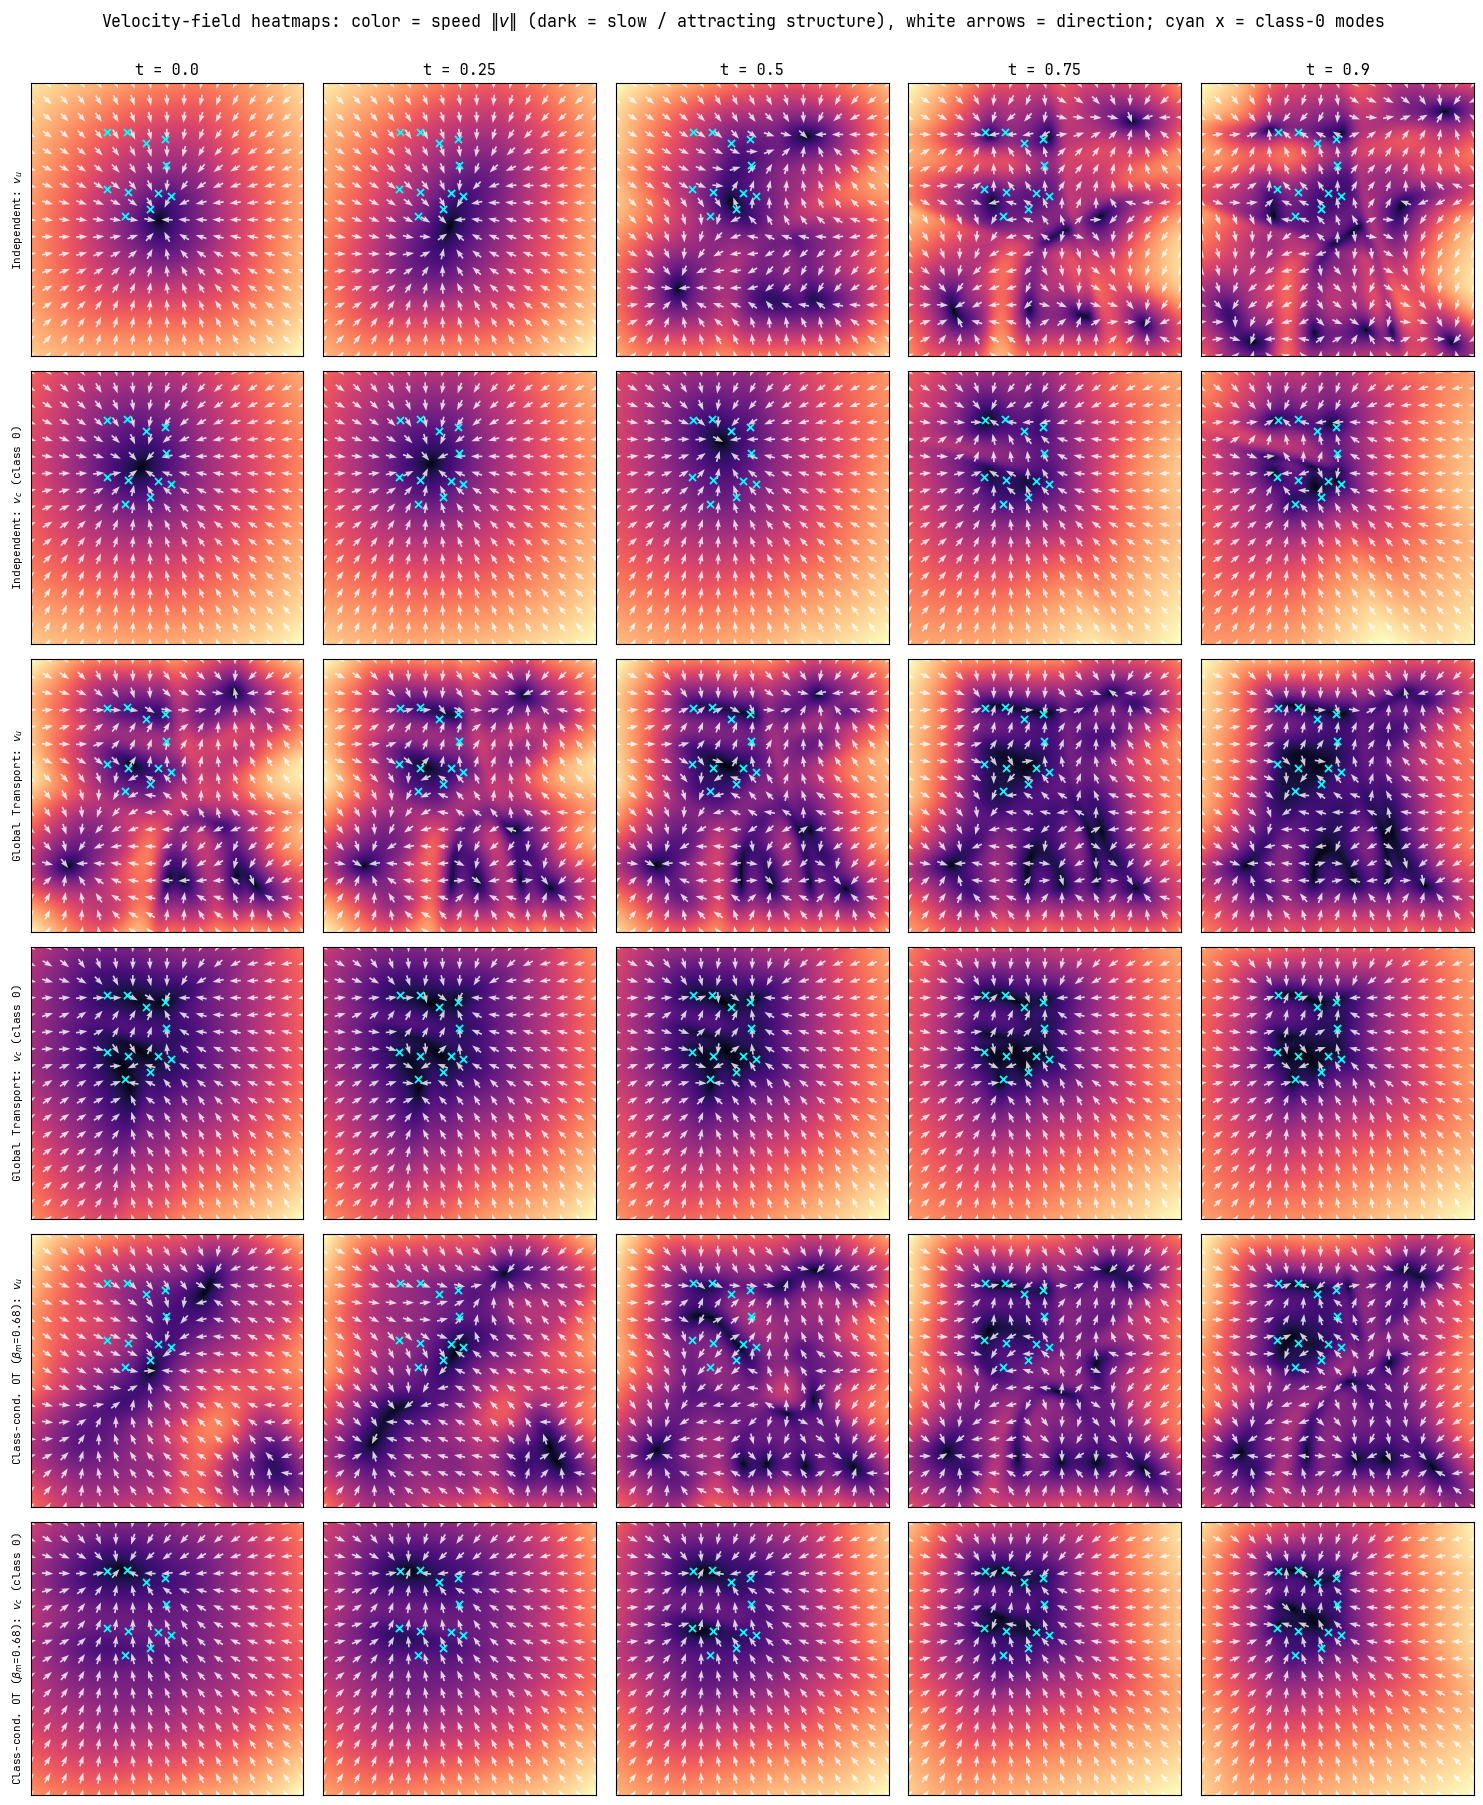

In [7]:
def _field(m, P, G, t, c_tok):
    '''Velocity field of model m on the G x G grid of points P at time t, class token c_tok.'''
    tt = torch.full((len(P),), float(t))
    cc = torch.full((len(P),), c_tok, dtype=torch.long)
    with torch.no_grad():
        v = m(P, tt, cc).numpy()
    return v[:, 0].reshape(G, G), v[:, 1].reshape(G, G)

# speed heatmaps: color = ||v||, sparse white unit arrows = direction
from matplotlib.colors import PowerNorm

GH, GQ = 110, 17
ghx = np.linspace(-BF, BF, GH)
XH, YH = np.meshgrid(ghx, ghx)
PH = torch.tensor(np.stack([XH.ravel(), YH.ravel()], 1).astype(np.float32))
gqx = np.linspace(-BF, BF, GQ)
XQ, YQ = np.meshgrid(gqx, gqx)
PQ = torch.tensor(np.stack([XQ.ravel(), YQ.ravel()], 1).astype(np.float32))

rows = []
for cp in COUPLINGS:
    rows.append((cp, NULL, STYLE[cp][0] + ": $v_u$"))
    rows.append((cp, C0, STYLE[cp][0] + f": $v_c$ (class {C0})"))

fig, ax = plt.subplots(len(rows), len(TS),
                       figsize=(3.0 * len(TS), 3.0 * len(rows)), squeeze=False)
for r, (cp, tok, lab) in enumerate(rows):
    for k, t in enumerate(TS):
        a = ax[r, k]
        U, V = _field(models[cp], PH, GH, t, tok)
        sp = np.sqrt(U ** 2 + V ** 2)
        a.imshow(sp, origin="lower", extent=[-BF, BF, -BF, BF], cmap="magma",
                 norm=PowerNorm(gamma=0.6, vmin=0, vmax=sp.max()))
        Uq, Vq = _field(models[cp], PQ, GQ, t, tok)
        mq = np.sqrt(Uq ** 2 + Vq ** 2)
        a.quiver(XQ, YQ, Uq / (mq + 1e-9), Vq / (mq + 1e-9), color="w",
                 alpha=0.8, pivot="mid", scale=24, width=0.006, headwidth=3.5)
        a.scatter(m0[:, 0], m0[:, 1], marker="x", color="cyan", s=26, linewidths=1.3)
        if r == 0: a.set_title(f"t = {t}", fontsize=11)
        if k == 0: a.set_ylabel(lab, fontsize=8)
        a.set_xlim(-BF, BF); a.set_ylim(-BF, BF)
        a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
plt.suptitle(r"Velocity-field heatmaps: color = speed $\|v\|$ (dark = slow / attracting "
             "structure), white arrows = direction; cyan x = class-0 modes",
             y=1.0, fontsize=12)
plt.tight_layout(); plt.show()


## 7. Divergence of the velocity field

$\nabla \cdot v$ on a dense grid (finite differences): **blue = contraction** (probability mass
being squeezed — attractors, and at strong guidance the signature of mode collapse),
**red = expansion**. 

We observe the contraction-expansion is present in independent and class-conditional OT (yoyo). Global Transport field remains stable over sampling time (no yoyo).

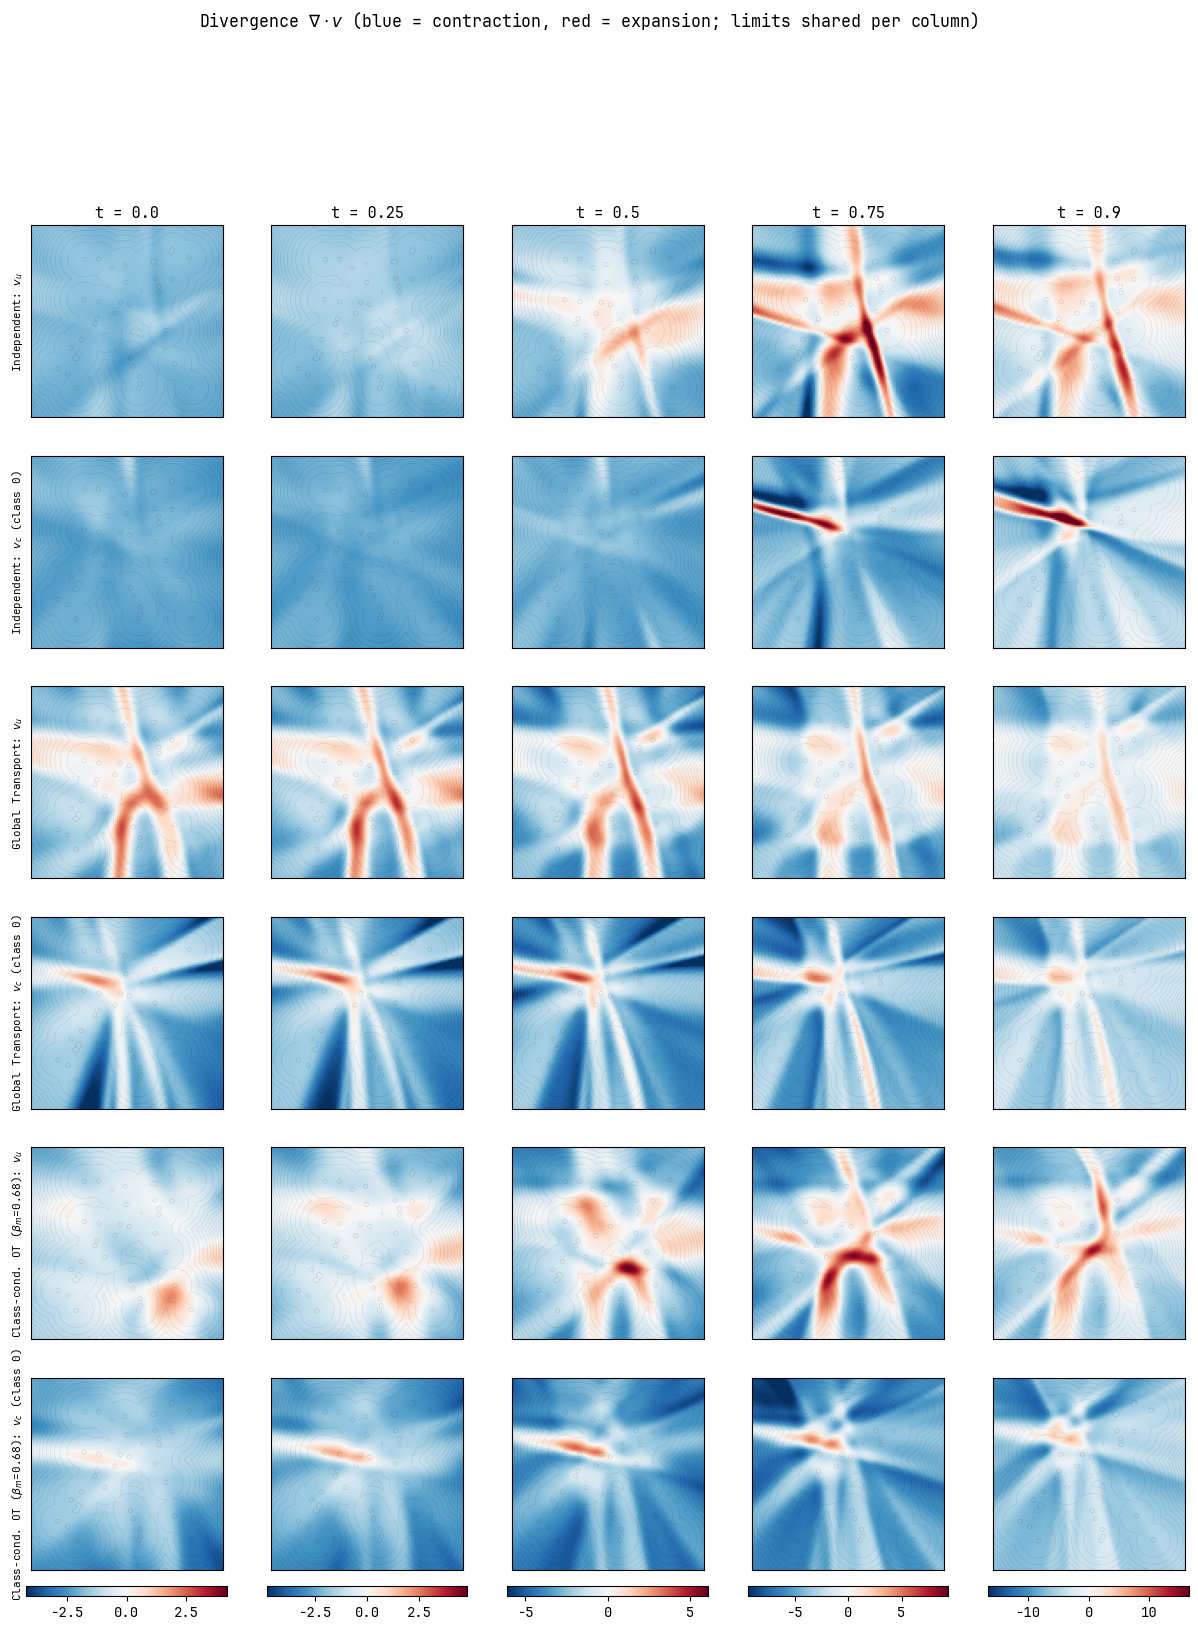

In [8]:
# target log-density on a fine grid, drawn as contours behind the divergence maps
gx2 = np.linspace(-BF, BF, 200)
X2, Y2 = np.meshgrid(gx2, gx2)
LP2 = log_prob(np.stack([X2.ravel(), Y2.ravel()], 1).astype(np.float32)).reshape(200, 200)

GD = 110
gxd = np.linspace(-BF, BF, GD)
dxd = gxd[1] - gxd[0]
XD, YD = np.meshgrid(gxd, gxd)
PD = torch.tensor(np.stack([XD.ravel(), YD.ravel()], 1).astype(np.float32))

def div_field(m, t, c_tok):
    U, V = _field(m, PD, GD, t, c_tok)
    return np.gradient(U, dxd, axis=1) + np.gradient(V, dxd, axis=0)

rows = []
for cp in COUPLINGS:
    rows.append((cp, NULL, STYLE[cp][0] + ": $v_u$"))
    rows.append((cp, C0, STYLE[cp][0] + f": $v_c$ (class {C0})"))

fig, ax = plt.subplots(len(rows), len(TS),
                       figsize=(3.0 * len(TS), 3.0 * len(rows)), squeeze=False)
for k, t in enumerate(TS):
    D = [div_field(models[cp], t, tok) for cp, tok, _ in rows]
    vm = max(np.percentile(np.abs(Dk), 99) for Dk in D)
    for r, (cp, tok, lab) in enumerate(rows):
        a = ax[r, k]
        im = a.imshow(D[r], origin="lower", extent=[-BF, BF, -BF, BF],
                      cmap="RdBu_r", vmin=-vm, vmax=vm)
        a.contour(X2, Y2, LP2, levels=14, colors="k", linewidths=0.2, alpha=0.3)
        if r == 0: a.set_title(f"t = {t}", fontsize=11)
        if k == 0: a.set_ylabel(lab, fontsize=8)
        a.set_xlim(-BF, BF); a.set_ylim(-BF, BF)
        a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
    fig.colorbar(im, ax=ax[:, k].tolist(), location="bottom", fraction=0.018, pad=0.012)
plt.suptitle(r"Divergence $\nabla \cdot v$ (blue = contraction, red = expansion; "
             "limits shared per column)", y=1.0, fontsize=12)
plt.show()

## 8. Guidance-norm integral vs CFG scale

The integral $\int_0^1 \mathbb{E}\|v_c - v_u\|\,dt$ measured along the actual sampling
trajectories (mean over the 4 classes, 1000 samples each), swept over $w \in [1, 20]$, for
all three couplings. 

independent: guidance-integral sweep done


ot: guidance-integral sweep done


ccot: guidance-integral sweep done


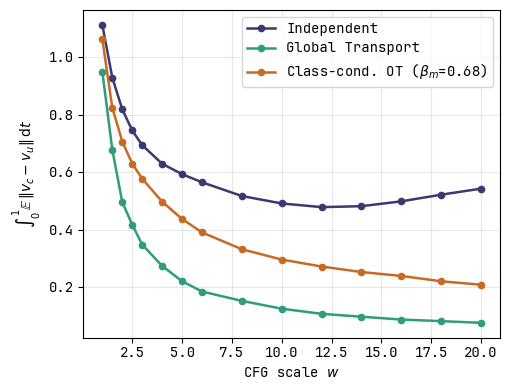

In [9]:
# paper figure: guidance-norm integral vs CFG scale, one curve per coupling
PAPER_G_ROWS   = COUPLINGS
PAPER_G_WS     = [1.0, 1.5, 2.0, 2.5, 3.0, 4.0, 5.0, 6.0, 8.0,
                  10.0, 12.0, 14.0, 16.0, 18.0, 20.0]
os.makedirs("paper", exist_ok=True)

torch.manual_seed(5)
gint = {}
for cp in PAPER_G_ROWS:
    vals = []
    for w in PAPER_G_WS:
        gs = [sample(models[cp], c, 1000, float(w), return_gnorm=True)[1].mean()
              for c in range(N_CLASS)]
        vals.append(np.mean(gs))
    gint[cp] = np.array(vals)
    print(f"{cp}: guidance-integral sweep done")

fig, a = plt.subplots(figsize=(5.2, 4.0))
for cp in PAPER_G_ROWS:
    a.plot(PAPER_G_WS, gint[cp], "o-", color=STYLE[cp][1], ms=4.5, lw=1.8,
           label=STYLE[cp][0])
a.set_xlabel("CFG scale $w$")
a.set_ylabel(r"$\int_0^1 \mathbb{E}\,\|v_c - v_u\|\,\mathrm{d}t$")
a.grid(alpha=0.3)
a.legend(fontsize=10)
plt.tight_layout()
fig.savefig(os.path.join("paper", "fab4_guidance_norm_integral.pdf"),
            bbox_inches="tight")
plt.show()